# Wildfire over a hill

The model follows temperature $T$ (K) and remaining dry fuel $Y$ in each horizontal cell. Hot fuel burns and releases heat. Heat spreads to neighbours, moves with the effective flow, and escapes to the surrounding air. Moisture absorbs heat before the fuel ignites.

The ground has a slope and a curved hill. The velocity is $\mathbf v=\beta\mathbf w+\gamma\nabla Z$: wind and terrain slope both affect spread. This is a 2.5D model. The equations are averaged over vegetation height; the 3D view places their 2D solution at the actual ground elevation. See [Navas-Montilla et al., Secs. 2.1–2.3](https://arxiv.org/html/2412.04517v2).

Plots stay in this notebook. The simulation also writes an XDMF/HDF5 time series under `downloads/notebook/` for animation in ParaView.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from wildfire_model.helpers import burned_area
from wildfire_model.inputs.fields import evaluate_field
from wildfire_model.inputs.reference_cases_2d import terrain_fire_case
from wildfire_model.main import run_complete_case

## Set up the terrain

The domain is 40 m by 32 m. The ground combines a 4% slope with a 6 m Gaussian hill. A 2 m hot circle starts at $(9,16)$ m, with temperature 670 K and unburned fuel everywhere. Wind is 1 m/s toward increasing $x$ before the model's wind correction. S2M moisture is 0.1 on a dry basis. Material properties retain the package defaults.

The notebook uses a smaller mesh than the command-line terrain run. Both use the same case definition.

In [2]:
case = terrain_fire_case(nx=64, ny=48, duration=120.0, frames=61)
mesh = case.mesh
initial = case.initial_state
configuration = case.configuration
times = case.output_times
project_root = Path.cwd().parent if Path.cwd().name == "examples" else Path.cwd()
output_directory = project_root / "downloads" / "notebook"
print(f"Cell field shape: {mesh.shape}; saved frames: {len(times)}")

Cell field shape: (48, 64); saved frames: 61


## Advance the fire

The solver chooses steps below its stability limit and saves the requested snapshots. Here, snapshots are 2 seconds apart. The checks below catch nonphysical values; the table samples four times from the run.

In [3]:
result = run_complete_case(case, output_directory=output_directory)
assert result.temperature.shape == (len(times), *mesh.shape)
assert np.isfinite(result.temperature).all()
assert np.all(result.temperature > 0.0)
assert np.all((result.biomass >= 0.0) & (result.biomass <= 1.0))

print("time (s)   max T (K)   min Y   area with Y < 0.99 (m²)")
for index in np.linspace(0, len(times) - 1, 4, dtype=int):
    temperature = result.temperature[index]
    biomass = result.biomass[index]
    area = burned_area(biomass, mesh)
    time = result.times[index]
    print(f"{time:8.0f}   {temperature.max():9.1f}   {biomass.min():.3f}   {area:8.2f}")
print("ParaView: downloads/notebook/series.xdmf")

time (s)   max T (K)   min Y   area with Y < 0.99 (m²)
       0       670.0   1.000       0.00
      40      1161.0   0.690      19.17
      80      1275.0   0.455      35.83
     120      1368.5   0.301      61.67
ParaView: downloads/notebook/series.xdmf


## Read the result

The top row shows temperature; the bottom row shows fuel remaining at the same times. Both use fixed colour scales, so changes between panels are comparable. The hot region extends beyond the original circle before every warm cell has consumed fuel.

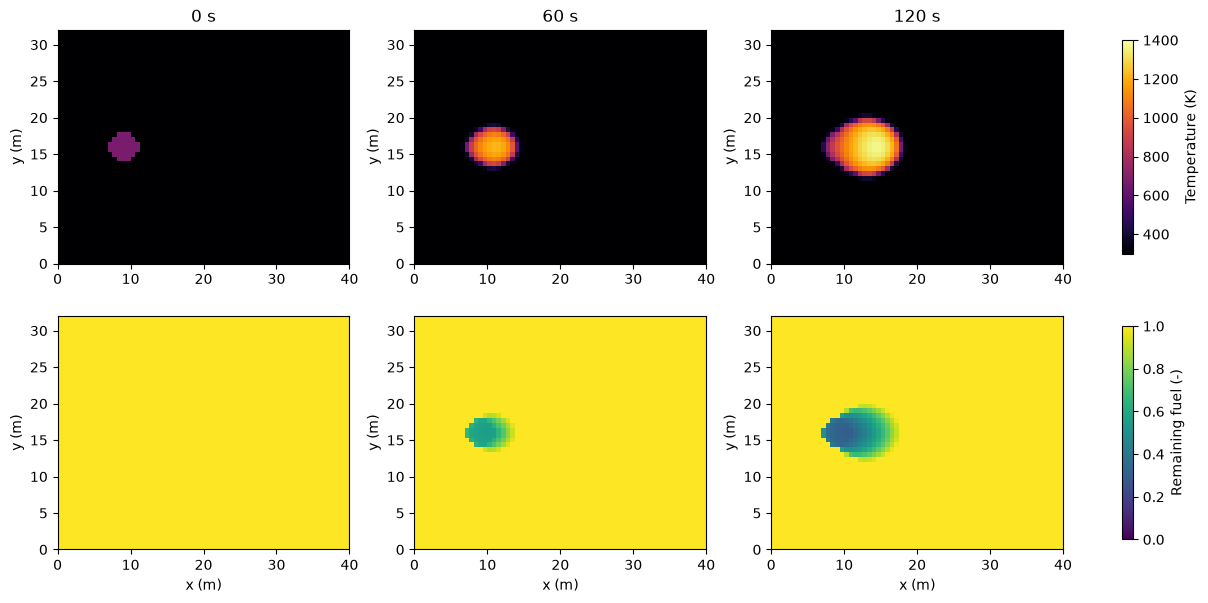

In [4]:
temperature_max = 100.0 * np.ceil(result.temperature.max() / 100.0)
snapshot_indices = (0, len(times) // 2, len(times) - 1)
figure, axes = plt.subplots(2, 3, figsize=(12, 6), constrained_layout=True)
extent = (mesh.x_min, mesh.x_max, mesh.y_min, mesh.y_max)
for column, index in enumerate(snapshot_indices):
    heat = axes[0, column].imshow(
        result.temperature[index],
        origin="lower",
        extent=extent,
        vmin=300,
        vmax=temperature_max,
        cmap="inferno",
    )
    fuel = axes[1, column].imshow(
        result.biomass[index],
        origin="lower",
        extent=extent,
        vmin=0.0,
        vmax=1.0,
        cmap="viridis",
    )
    axes[0, column].set_title(f"{result.times[index]:.0f} s")
    axes[1, column].set_xlabel("x (m)")
    for row in (0, 1):
        axes[row, column].set_ylabel("y (m)")
figure.colorbar(heat, ax=axes[0, :], label="Temperature (K)", shrink=0.8)
figure.colorbar(fuel, ax=axes[1, :], label="Remaining fuel (-)", shrink=0.8)
plt.show()

## See the ground in 3D

The height below is terrain elevation, not temperature or flame height. Colour shows the final temperature. The XDMF export uses the same elevation field and keeps temperature and fuel attached to the original cells.

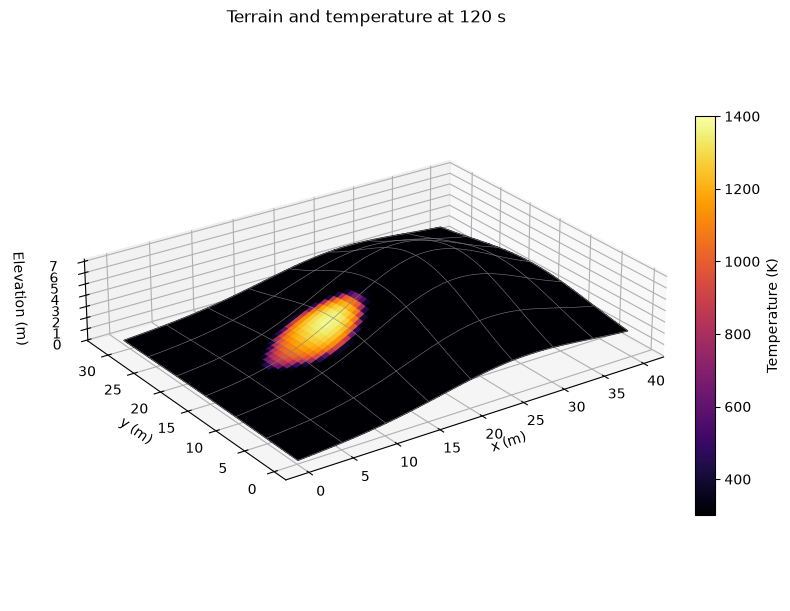

In [5]:
x, y = mesh.cell_centers
height = evaluate_field(configuration.elevation, mesh, name="terrain", time=0.0)
normalization = plt.Normalize(300.0, temperature_max)
colormap = plt.get_cmap("inferno")
figure = plt.figure(figsize=(10, 6), constrained_layout=True)
axis = figure.add_subplot(projection="3d")
axis.plot_surface(
    x,
    y,
    height,
    facecolors=colormap(normalization(result.temperature[-1])),
    rstride=1,
    cstride=1,
    shade=False,
)
axis.plot_wireframe(x, y, height, rstride=8, cstride=8, color="0.5", linewidth=0.4)
axis.set(xlabel="x (m)", ylabel="y (m)", zlabel="Elevation (m)")
axis.set_box_aspect((40, 32, 8))
axis.view_init(elev=25, azim=-125)
axis.set_title(f"Terrain and temperature at {result.times[-1]:.0f} s")
figure.colorbar(
    plt.cm.ScalarMappable(norm=normalization, cmap=colormap),
    ax=axis,
    label="Temperature (K)",
    shrink=0.7,
)
plt.show()

The arrays remain available as `result.temperature` and `result.biomass` in `(time, y, x)` order. Change the mesh, duration, or saved-frame count in `terrain_fire_case` above and rerun the cells.

To animate the result, open `downloads/notebook/series.xdmf` in ParaView and click **Apply**. Keep `series.h5` in the same directory. Choose `temperature_K` or `remaining_fuel` as the cell colour, set a fixed colour range, then press **Play**. **File → Save Animation** records the sequence; the [ParaView guide](https://docs.paraview.org/en/latest/UsersGuide/animation.html) describes those controls.